# Tomografia de Estados Quânticos com Regularização Entrópica

Notebook organizado por seções de experimentos, utilizando as funções modularizadas no pacote `entropy_reg` e a biblioteca `quantum_tomography`.

In [46]:
import sys
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.linalg as sla
import qutip as qtp
from matplotlib.ticker import FuncFormatter, LogLocator
from qutip.wigner import wigner_transform
from scipy.linalg import expm
from scipy.optimize import least_squares

# Importa as bibliotecas desenvolvidas para o projeto
import quantum_tomography as qt
import entropy_reg as er
from entropy_reg.dual import dual_gradient, normalizar_rho, rho_a_partir_de_u
from entropy_reg.methods.gradient_descent import gradient_descent, reconstruct_pi
from entropy_reg.methods.sgd import reconstruct_spi, sgd, sgd_mem
from entropy_reg.observables import grad_completo, medidas_pauli, montar_observaveis_pauli
from entropy_reg.states import estado_gibbs, hamiltoniano_ising, rho_gibbs
from entropy_reg.utils import fmt_bytes

## 1. Medidas incompletas

Verificação de sanidade (*sanity check*): testamos se os métodos de Gradient Descent e Stochastic Gradient Descent funcionam para um mesmo problema subdeterminado de 1 qubit (medindo apenas $I$, $X$ e $Y$, sem $Z$) com os mesmos parâmetros.

In [47]:
Q = [np.eye(2), qt.pauli_string_to_matrix("X"), qt.pauli_string_to_matrix("Y")]
q = [1, 0.7, 0.4]
H = 0
epsilon = 1

# Teste com Gradient Descent
pistar_data = reconstruct_pi(H, Q, q, epsilon, lr=1, max_iters=10000, tol=1e-6)
pistar = pistar_data[0]

print("Com o método de Gradient Descent:")
print("Valores das médias com os observáveis I, Sigma_x, Sigma_y:")
print(np.trace(pistar), np.trace(pistar @ Q[1]), np.trace(pistar @ Q[2]))
print("Número de iterações: ", pistar_data[2])
print("Matriz reconstruída pi*:")
print(pistar)

# Teste com Stochastic Gradient Descent
stocpistar_data = reconstruct_spi(H, Q, q, epsilon, max_iters=5000, lr=1, tol=1e-6, k=2, count_it=1)
stocpistar, stoc_u_opt, stoc_n_it, stoc_pi_grad = stocpistar_data
stoc_grad_data = np.array(stoc_pi_grad)

print("Com o método de Stochastic Gradient Descent:")
print("Valores das médias com os observáveis I, Sigma_x, Sigma_y:")
print(np.trace(stocpistar), np.trace(stocpistar @ Q[1]), np.trace(stocpistar @ Q[2]))
print("iterações:", stoc_n_it)
print("Matriz reconstruída pi*:")
print(stocpistar)

Com o método de Gradient Descent:
Valores das médias com os observáveis I, Sigma_x, Sigma_y:
(1.0000008181897577-4.1777418156342424e-17j) (0.7000002472614089-2.7755575615628914e-17j) (0.4000001412922337+0j)
Número de iterações:  56
Matriz reconstruída pi*:
[[0.50000041+4.80325509e-18j 0.35000012-2.00000071e-01j]
 [0.35000012+2.00000071e-01j 0.50000041-4.65806732e-17j]]
Com o método de Stochastic Gradient Descent:
Valores das médias com os observáveis I, Sigma_x, Sigma_y:
(1.0000000001282152-1.0194436133805656e-17j) (0.6999999783829212-5.551115123125783e-17j) (0.3999999874537122+5.551115123125783e-17j)
iterações: 100
Matriz reconstruída pi*:
[[0.5       +2.53539514e-17j 0.34999999-1.99999994e-01j]
 [0.34999999+1.99999994e-01j 0.5       -3.55483875e-17j]]


## 2. Comparação: Gradient Descent × Stochastic

Definimos um estado-alvo de 3 qubits para comparar a convergência, o tempo de execução e a norma de Frobenius entre o Gradient Descent completo e o método estocástico (SGD).

In [48]:
n_qubits = 3
estado_alvo = qt.random_mixture_of_pures(dim=2**n_qubits, rank=4, seed=17)

nomes_obs, Q = montar_observaveis_pauli(n_qubits)
q = qt.measure_observables(estado_alvo, nomes_obs)
H = np.zeros((2**n_qubits, 2**n_qubits), dtype=complex)
epsilon = 1.0

print(estado_alvo)
print("Número de observáveis:", len(Q))
print("Traço do estado-alvo:", np.trace(estado_alvo.rho).real)
print("Autovalores do estado-alvo:", np.linalg.eigvalsh(estado_alvo.rho))

<QuantState (3 qubits, Misto (posto 4), pureza=0.336)>
Número de observáveis: 64
Traço do estado-alvo: 1.0
Autovalores do estado-alvo: [-4.88560586e-17 -2.24320419e-17  3.35882833e-18  3.35699553e-17
  9.90608868e-02  1.26475398e-01  3.13921218e-01  4.60542498e-01]


In [49]:
lr_comparacao = 0.5
tol = 1e-6
check_every = 10
max_iters = 100000

# Gradient Descent completo
t0 = time.perf_counter()
gd_data = er.gradient_descent(
    H, Q, q, epsilon, max_iters=max_iters, lr=lr_comparacao, tol=tol
)
tempo_gd = time.perf_counter() - t0
u_gd, it_gd, us_gd, grad_gd = gd_data

# Método estocástico com k coordenadas por iteração
t0 = time.perf_counter()
u_st, it_st, hist_st = er.sgd(
    H, Q, q, epsilon, k=len(Q)//2, lr=lr_comparacao,
    n_iter=max_iters, tol=tol, seed=0,
    check_every=check_every, count_it=check_every
)
tempo_st = time.perf_counter() - t0

rho_gd = normalizar_rho(rho_a_partir_de_u(u_gd, H, Q, epsilon))
rho_st = normalizar_rho(rho_a_partir_de_u(u_st, H, Q, epsilon))

print("Gradient Descent")
print("iterações:", it_gd, "| tempo (s):", round(tempo_gd, 4))
print("norma final do gradiente:", np.linalg.norm(er.dual_gradient(u_gd, H, Q, q, epsilon)))
print("norma de Frobenius:", qt.frobenius_distance(rho_gd, estado_alvo.rho))

print("\nMétodo estocástico")
print("iterações:", it_st, "| tempo (s):", round(tempo_st, 4))
print("norma final do gradiente:", np.linalg.norm(er.dual_gradient(u_st, H, Q, q, epsilon)))
print("norma de Frobenius:", qt.frobenius_distance(rho_st, estado_alvo.rho))

Gradient Descent
iterações: 100000 | tempo (s): 16.404
norma final do gradiente: 1.4139716064896302e-05
norma de Frobenius: 7.656648296013692e-06

Método estocástico
iterações: 100000 | tempo (s): 16.2095
norma final do gradiente: 3.024788892237474e-05
norma de Frobenius: 1.637183612047844e-05


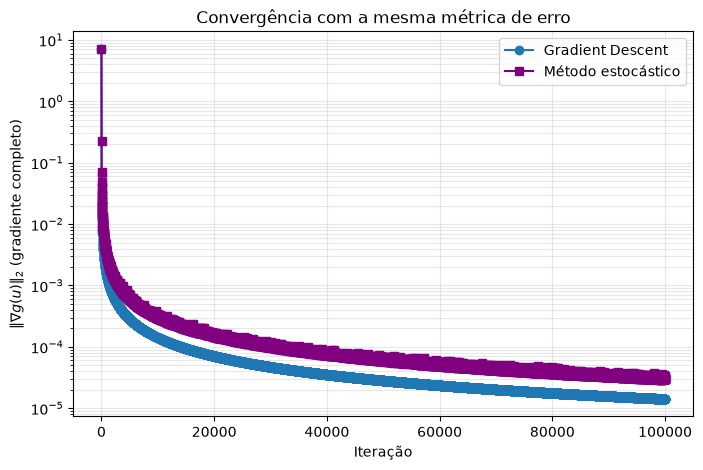

In [50]:
# O GD registra todos os passos; selecionamos os mesmos instantes usados no SGD.
hist_gd = np.asarray(grad_gd)
hist_gd = hist_gd[hist_gd[:, 0] % check_every == 0]
grad_gd_final = np.linalg.norm(er.dual_gradient(u_gd, H, Q, q, epsilon))
if hist_gd[-1, 0] != it_gd:
    hist_gd = np.vstack([hist_gd, [it_gd, grad_gd_final]])

hist_st = np.asarray(hist_st)
grad_inicial = np.linalg.norm(
    er.dual_gradient(np.zeros(len(q)), H, Q, q, epsilon)
)
hist_st = np.vstack([[0, grad_inicial], hist_st])

plt.figure(figsize=(8, 5))
plt.semilogy(hist_gd[:, 0], hist_gd[:, 1], "o-", label="Gradient Descent")
plt.semilogy(hist_st[:, 0], hist_st[:, 1], "s-", label="Método estocástico", color="purple")
plt.xlabel("Iteração")
plt.ylabel(r"$\|\nabla g(u)\|_2$ (gradiente completo)")
plt.title("Convergência com a mesma métrica de erro")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

### Comparação em múltiplos estados-alvo (16 seeds)

Repetimos a comparação entre Gradient Descent e Stochastic Gradient Descent para 16 estados-alvo distintos de 3 qubits (posto 8), consolidando iterações, tempo, norma do gradiente e norma de Frobenius em uma tabela e grade de gráficos.

In [51]:
n_qubits = 3
rank = 8
seeds_estados = [17, 23, 42, 101,
                2024, 93284, 17348, 958,
                999, 101010, 6767, 123, 
                432, 50, 67, 474]   # 5 estados-alvo diferentes

nomes_obs, Q = montar_observaveis_pauli(n_qubits)
H = np.zeros((2**n_qubits, 2**n_qubits), dtype=complex)
epsilon = 1.0

lr_comparacao = 0.5
tol = 1e-6
check_every = 10
max_iters = 100000
seed_sgd = 0

In [52]:
def rodar_teste(seed_estado):
    estado_alvo = qt.random_mixture_of_pures(
        dim=2**n_qubits, rank=rank, seed=seed_estado
    )
    q = qt.measure_observables(estado_alvo, nomes_obs)

    # Gradient Descent completo
    t0 = time.perf_counter()
    u_gd, it_gd, us_gd, grad_gd = er.gradient_descent(
        H, Q, q, epsilon, max_iters=max_iters, lr=lr_comparacao, tol=tol
    )
    tempo_gd = time.perf_counter() - t0

    # Método estocástico
    t0 = time.perf_counter()
    u_st, it_st, hist_st = er.sgd(
        H, Q, q, epsilon, k=len(Q)//2, lr=lr_comparacao,
        n_iter=max_iters, tol=tol, seed=seed_sgd,
        check_every=check_every, count_it=check_every
    )
    tempo_st = time.perf_counter() - t0

    rho_gd = normalizar_rho(rho_a_partir_de_u(u_gd, H, Q, epsilon))
    rho_st = normalizar_rho(rho_a_partir_de_u(u_st, H, Q, epsilon))

    grad_final_gd = np.linalg.norm(er.dual_gradient(u_gd, H, Q, q, epsilon))
    grad_final_st = np.linalg.norm(er.dual_gradient(u_st, H, Q, q, epsilon))

    # Histórico do GD nos mesmos instantes do SGD
    hist_gd = np.asarray(grad_gd)
    hist_gd = hist_gd[hist_gd[:, 0] % check_every == 0]
    if hist_gd[-1, 0] != it_gd:
        hist_gd = np.vstack([hist_gd, [it_gd, grad_final_gd]])

    # Histórico do SGD com o ponto inicial
    grad_inicial = np.linalg.norm(
        er.dual_gradient(np.zeros(len(q)), H, Q, q, epsilon)
    )
    hist_st = np.vstack([[0, grad_inicial], np.asarray(hist_st)])

    return {
        "seed_estado": seed_estado,
        "autovalores": np.linalg.eigvalsh(estado_alvo.rho),
        "it_gd": it_gd, "tempo_gd": tempo_gd,
        "grad_gd": grad_final_gd,
        "frob_gd": qt.frobenius_distance(rho_gd, estado_alvo.rho),
        "it_st": it_st, "tempo_st": tempo_st,
        "grad_st": grad_final_st,
        "frob_st": qt.frobenius_distance(rho_st, estado_alvo.rho),
        "hist_gd": hist_gd, "hist_st": hist_st,
    }


resultados = []
for s in seeds_estados:
    print(f"Rodando estado com seed={s} ...")
    resultados.append(rodar_teste(s))

Rodando estado com seed=17 ...
Rodando estado com seed=23 ...
Rodando estado com seed=42 ...
Rodando estado com seed=101 ...
Rodando estado com seed=2024 ...


KeyboardInterrupt: 

,seed do estado,it GD,it SGD,tempo GD (s),tempo SGD (s),||grad|| GD,||grad|| SGD,norma Frobenius GD,norma Frobenius SGD
0,17,228,450,0.038000,0.069300,9.978e-07,9.208e-07,3.880e-07,3.424e-07
1,23,2255,4580,0.371900,0.718200,9.999e-07,9.702e-07,3.868e-07,3.797e-07
2,42,305,610,0.050600,0.098100,9.936e-07,8.757e-07,3.919e-07,3.479e-07
3,101,1159,2330,0.192300,0.366000,9.997e-07,9.612e-07,3.834e-07,3.664e-07
4,2024,100000,250,16.517800,0.038600,1.059706,7.669e-07,0.106797,2.715e-07
5,93284,433,870,0.070900,0.134900,9.919e-07,9.766e-07,3.752e-07,3.638e-07
6,17348,175,350,0.029400,0.054600,9.705e-07,8.383e-07,3.670e-07,3.115e-07
7,958,100000,250,16.429100,0.039000,0.457798,7.246e-07,0.056084,2.697e-07
8,999,306,620,0.051100,0.097900,9.967e-07,9.556e-07,3.851e-07,3.617e-07
9,101010,463,940,0.076400,0.145300,9.915e-07,9.798e-07,3.826e-07,3.798e-07



Média sobre os 5 estados:
it GD                 12903.187500
it SGD                  846.250000
tempo GD (s)              2.125900
tempo SGD (s)             0.132350
||grad|| GD               0.094845
||grad|| SGD             8.640e-07
norma Frobenius GD        0.010180
norma Frobenius SGD      3.257e-07
dtype: float64


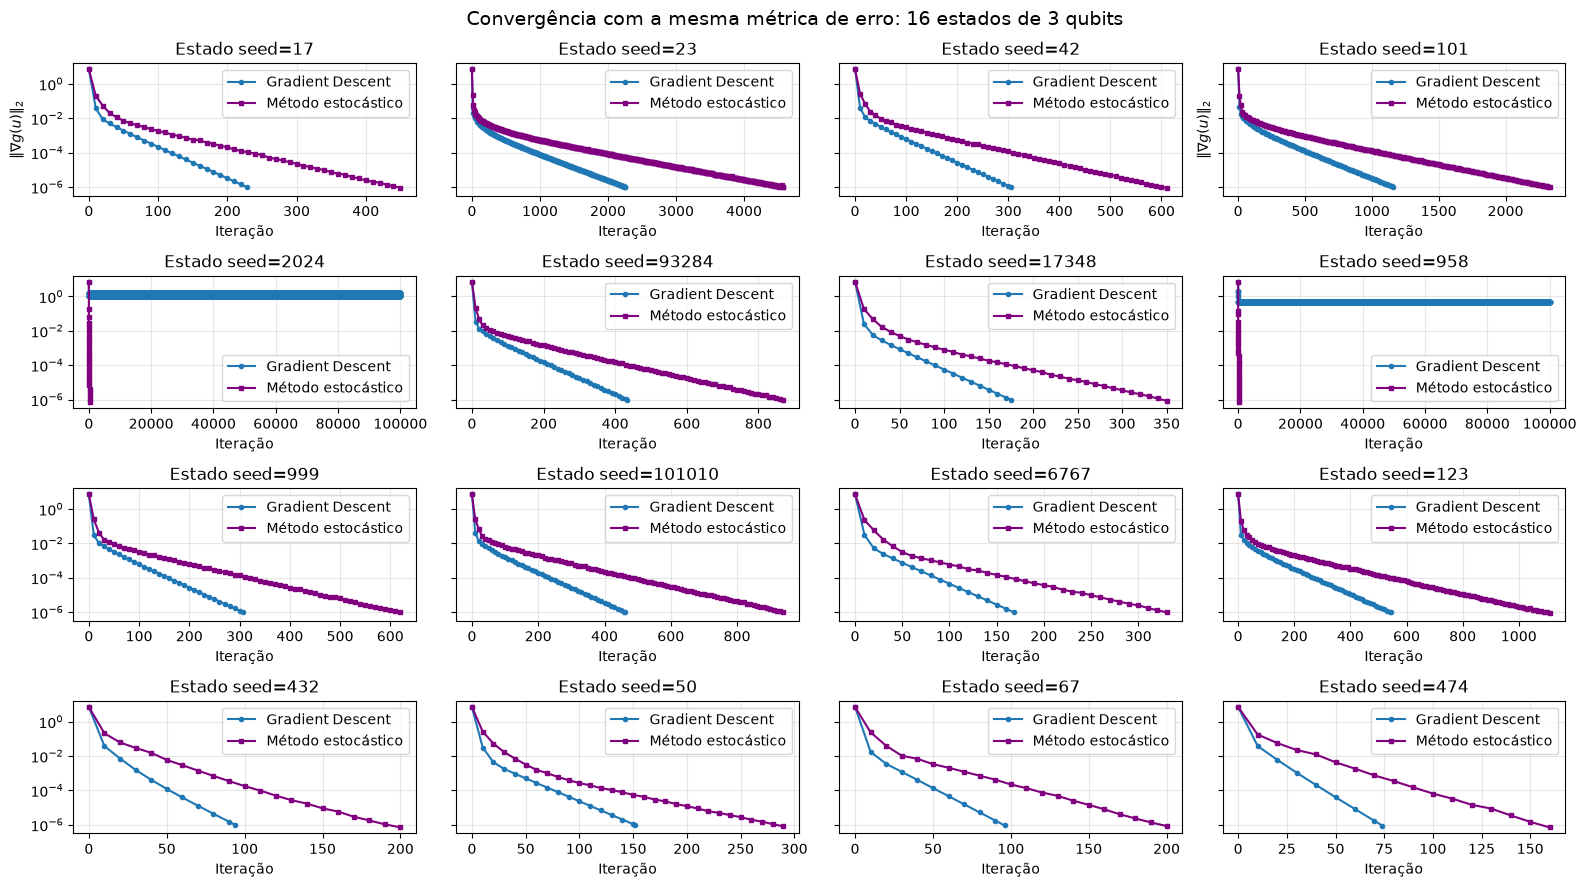

In [ ]:
# ---------- Tabela-resumo ----------
tabela = pd.DataFrame([{
    "seed do estado": r["seed_estado"],
    "it GD": r["it_gd"],
    "it SGD": r["it_st"],
    "tempo GD (s)": round(r["tempo_gd"], 4),
    "tempo SGD (s)": round(r["tempo_st"], 4),
    "||grad|| GD": r["grad_gd"],
    "||grad|| SGD": r["grad_st"],
    "norma Frobenius GD": r["frob_gd"],
    "norma Frobenius SGD": r["frob_st"],
} for r in resultados])

pd.set_option("display.float_format", lambda x: f"{x:.3e}" if abs(x) < 1e-2 else f"{x:.6f}")
display(tabela)   # use print(tabela) se não estiver no Jupyter

print("\nMédia sobre os 5 estados:")
print(tabela.drop(columns="seed do estado").mean())

# ---------- Gráficos: um por seed ----------
fig, axs = plt.subplots(4, 4, figsize=(16, 9), sharey=True)
axs = axs.ravel()

for ax, r in zip(axs, resultados):
    ax.semilogy(r["hist_gd"][:, 0], r["hist_gd"][:, 1], "o-", ms=3, label="Gradient Descent")
    ax.semilogy(r["hist_st"][:, 0], r["hist_st"][:, 1], "s-", ms=3, label="Método estocástico", color="purple")
    ax.set_title(f"Estado seed={r['seed_estado']}")
    ax.set_xlabel("Iteração")
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()

axs[0].set_ylabel(r"$\|\nabla g(u)\|_2$")
axs[3].set_ylabel(r"$\|\nabla g(u)\|_2$")


plt.suptitle("Convergência com a mesma métrica de erro: 16 estados de 3 qubits", fontsize=14)
plt.tight_layout()
plt.show()

## 3. Variação de LR

Selecionamos o método estocástico por apresentar melhor escalabilidade de memória em dimensões maiores. Definimos um estado-alvo arbitrário de 3 qubits e avaliamos a convergência variando a taxa de aprendizado (*learning rate*).

In [53]:
n_qubits = 3
estado_alvo = qt.random_mixture_of_pures(dim=2**n_qubits, seed=35)

nomes_obs, Q = montar_observaveis_pauli(n_qubits)
q = qt.measure_observables(estado_alvo, nomes_obs)
H = np.zeros((2**n_qubits, 2**n_qubits), dtype=complex)

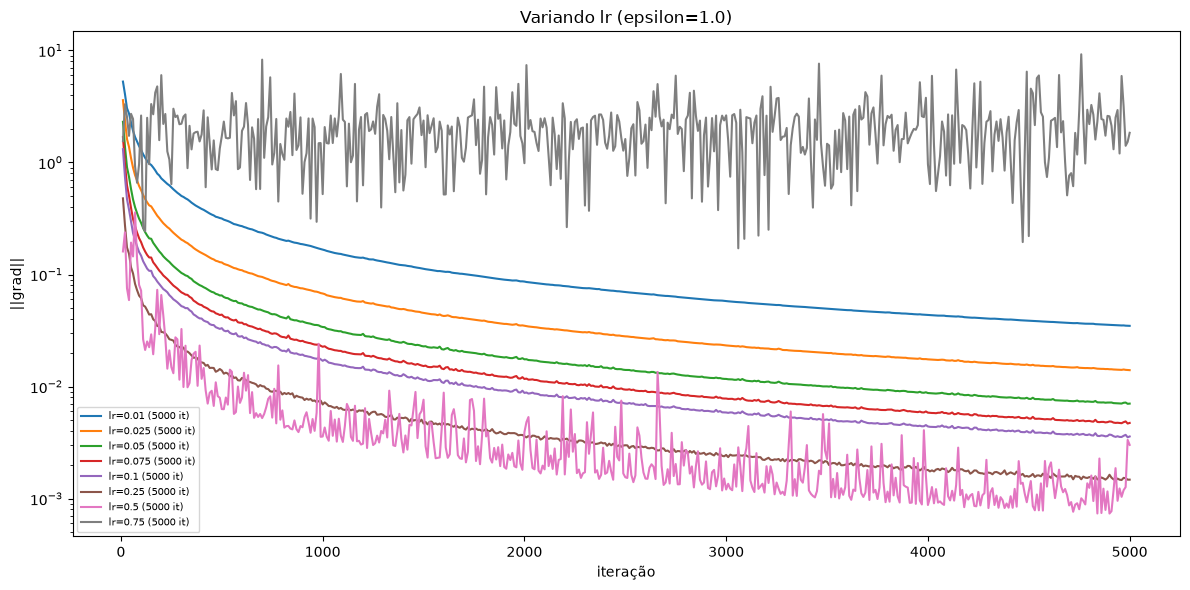

In [58]:
tol_fix = 1e-6
check_every_fix = 50
max_iters_fix = 5000

lr_values = [0.01, 0.025, 0.05, 0.075, 0.1, 0.25, 0.5, 0.75]
epsilon_fix = 1.0

k = len(Q) // 2


def rodar(lr, epsilon):
    u, n_it, hist = sgd(H, Q, q, epsilon, k=k, lr=lr, n_iter=max_iters_fix,
                        tol=tol_fix, seed=0, check_every=check_every_fix, count_it=10)
    hist = np.array(hist)
    return hist[:, 0], hist[:, 1], n_it


fig1, ax1 = plt.subplots(figsize=(12, 6))

for lr in lr_values:
    t, g, n_it = rodar(lr, epsilon_fix)
    ax1.semilogy(t, g, label=f"lr={lr} ({n_it} it)")

ax1.set_title(f"Variando lr (epsilon={epsilon_fix})")
ax1.set_xlabel("iteração")
ax1.set_ylabel("||grad||")
ax1.legend(fontsize=7)

plt.tight_layout()
plt.show()

## 4. Variação de $\epsilon$

Para o mesmo estado-alvo e com a taxa de aprendizado fixa, avaliamos o impacto do parâmetro de regularização entrópica $\epsilon$ (correspondente à temperatura) na convergência do SGD.

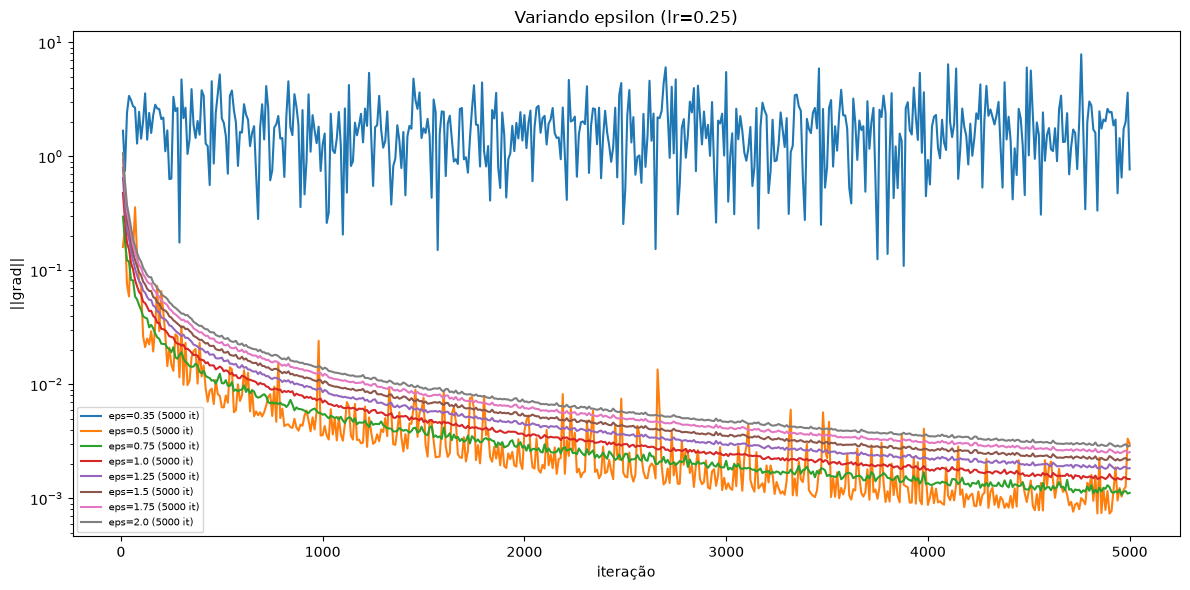

In [57]:
epsilon_values = [0.35, 0.5,0.75, 1.0, 1.25, 1.5, 1.75, 2.0]
lr_fix = 0.25

fig2, ax2 = plt.subplots(figsize=(12, 6))

for eps in epsilon_values:
    t, g, n_it = rodar(lr_fix, eps)
    ax2.semilogy(t, g, label=f"eps={eps} ({n_it} it)")

ax2.set_title(f"Variando epsilon (lr={lr_fix})")
ax2.set_xlabel("iteração")
ax2.set_ylabel("||grad||")
ax2.legend(fontsize=7)

plt.tight_layout()
plt.show()

## 5. Convergência de estados distintos

Definimos uma lista com diferentes classes de estados quânticos (puro, mistura de puros, estado térmico de Gibbs e totalmente misto) para verificar a convergência do SGD com regularização entrópica.

### Convergência com múltiplas execuções: estados despolarizados e estado de Gibbs

Avaliamos a mediana e a faixa mínimo–máximo de convergência do SGD sobre múltiplas sementes para estados puros despolarizados (variando $p$) e para o estado térmico de Gibbs, registrando também a divergência KL.

lr=0.25, epsilon=0.75, k=32/64, count_it=25, max_iters=10000

estado              pureza posto  iters   ||grad||   Tr(pi) norma Frob.         KL
Totalmente misto    0.1250     8    100   1.88e-11   1.0000    0.000000   0.00e+00
p=0.25              0.1797     8    100   3.27e-07   1.0000    0.000000   6.64e-14
p=0.50              0.3438     8    150   2.86e-07   1.0000    0.000000   7.57e-14
p=0.75              0.6172     8    300   1.67e-07   1.0000    0.000000   4.92e-14
p=0.90              0.8338     8    700   4.71e-07   1.0000    0.000000   8.04e-13
Puro                1.0000     1  10000   5.79e-04   1.0005    0.000564   5.27e-04
Mistura de puros    0.3129     4  10000   4.52e-04   1.0002    0.000221   3.01e-04
Gibbs (beta=1)      0.4785     8   9600   9.20e-07   1.0000    0.000000   8.31e-11


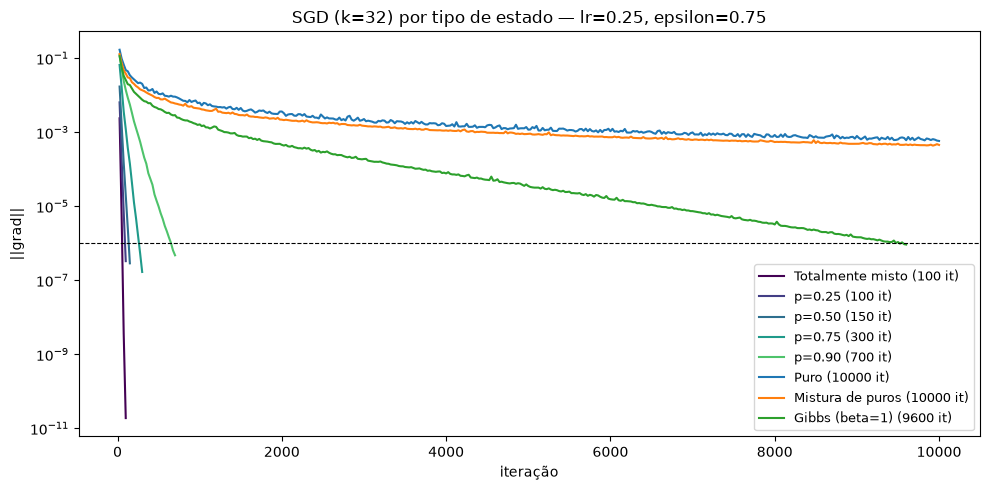

In [63]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm

n_qubits = 3
dim = 2**n_qubits

lr, epsilon = 0.25, 0.75
tol = 1e-6
check_every = 50
max_iters = 10000
count_it = 25

# Observáveis: as 4^n Paulis COM a identidade (a identidade fixa Tr(pi) = 1)
nomes_obs = qt.pauli_basis_strings(n_qubits, include_identity=True)
Q = [qt.pauli_string_to_matrix(s) for s in nomes_obs]
H = np.zeros((dim, dim), dtype=complex)     # H do problema de reconstrução
k = len(Q) // 2                              # batch = metade das coordenadas

# ----------------------------------------------------------------------
# Funções auxiliares para os estados-alvo
# ----------------------------------------------------------------------
def hamiltoniano_ising(n, g=1.0):
    Hf = np.zeros((2**n, 2**n), dtype=complex)
    for i in range(n - 1):
        s = ["I"] * n; s[i] = s[i + 1] = "Z"
        Hf -= qt.pauli_string_to_matrix("".join(s))
    for i in range(n):
        s = ["I"] * n; s[i] = "X"
        Hf -= g * qt.pauli_string_to_matrix("".join(s))
    return Hf

def estado_gibbs(Hf, beta):
    rho = expm(-beta * Hf)
    return qt.QuantState(rho / np.trace(rho).real)

def estado_depolarizado(seed, p):
    """rho = p |psi><psi| + (1-p) I/d  (p=1 puro, p=0 totalmente misto)."""
    psi = qt.random_pure_state(dim, seed=seed).rho
    return qt.QuantState(p * psi + (1 - p) * np.eye(dim) / dim)

def divergencia_kl(rho, u):
    """KL(rho || pi) sem logm: log pi = A - log Z, com A = (sum u_i Q_i - H)/eps."""
    A = (sum(ui * Qi for ui, Qi in zip(u, Q)) - H) / epsilon
    A = (A + A.conj().T) / 2
    if not np.all(np.isfinite(A)):
        return np.nan
    lam = np.linalg.eigvalsh(A)
    logZ = lam.max() + np.log(np.sum(np.exp(lam - lam.max())))
    ev = np.linalg.eigvalsh(rho)
    ev = ev[ev > 1e-12]
    kl = np.sum(ev * np.log(ev)) - np.real(np.trace(rho @ A)) + logZ
    return max(kl, 0.0)

# ----------------------------------------------------------------------
# Estados-alvo
# ----------------------------------------------------------------------
estados = {
    "Totalmente misto":  qt.maximally_mixed_state(dim),
    "p=0.25":            estado_depolarizado(35, 0.25),
    "p=0.50":            estado_depolarizado(35, 0.50),
    "p=0.75":            estado_depolarizado(35, 0.75),
    "p=0.90":            estado_depolarizado(35, 0.90),
    "Puro":              qt.random_pure_state(dim, seed=35),
    "Mistura de puros":  qt.random_mixture_of_pures(dim, rank=4, seed=35),
    "Gibbs (beta=1)":    estado_gibbs(hamiltoniano_ising(n_qubits), beta=1.0),
}

# ----------------------------------------------------------------------
# SGD em cada estado
# ----------------------------------------------------------------------
resultados = {}
print(f"lr={lr}, epsilon={epsilon}, k={k}/{len(Q)}, count_it={count_it}, max_iters={max_iters}\n")
print(f"{'estado':<18}{'pureza':>8}{'posto':>6}{'iters':>7}{'||grad||':>11}"
      f"{'Tr(pi)':>9}{'norma Frob.':>12}{'KL':>11}")

for nome, estado in estados.items():
    q = qt.measure_observables(estado, nomes_obs)
    with np.errstate(all="ignore"):
        u, n_it, hist = er.sgd(H, Q, q, epsilon, k=k, lr=lr, n_iter=max_iters, tol=tol,
                               seed=0, check_every=check_every, count_it=count_it)
    hist = np.array(hist)

    if np.all(np.isfinite(u)):
        pi = expm((sum(u_i * Q_i for u_i, Q_i in zip(u, Q)) - H) / epsilon)
        tr = np.real(np.trace(pi))
        g_final = np.linalg.norm(er.dual_gradient(u, H, Q, q, epsilon))
        frob = qt.frobenius_distance(estado.rho, pi / tr) if np.isfinite(tr) else np.nan
        kl = divergencia_kl(estado.rho, u)
    else:
        print(f"[AVISO] {nome}: u não finito, métricas = NaN")
        tr = g_final = frob = kl = np.nan

    resultados[nome] = (hist[:, 0], hist[:, 1], n_it)
    print(f"{nome:<18}{estado.purity:8.4f}{estado.rank:6d}{n_it:7d}{g_final:11.2e}"
          f"{tr:9.4f}{frob:12.6f}{kl:11.2e}")

# ----------------------------------------------------------------------
# Gráfico
# ----------------------------------------------------------------------
cores = {
    "Totalmente misto": plt.cm.viridis(0.00),
    "p=0.25":           plt.cm.viridis(0.18),
    "p=0.50":           plt.cm.viridis(0.36),
    "p=0.75":           plt.cm.viridis(0.54),
    "p=0.90":           plt.cm.viridis(0.72),
    "Puro":             "tab:blue",
    "Mistura de puros": "tab:orange",
    "Gibbs (beta=1)":   "tab:green",
}

fig, ax = plt.subplots(figsize=(10, 5))
for nome, (t, g, n_it) in resultados.items():
    ok = np.isfinite(g)
    ax.semilogy(t[ok], g[ok], color=cores[nome], label=f"{nome} ({n_it} it)")
ax.axhline(tol, color="k", ls="--", lw=0.8)
ax.set_xlabel("iteração")
ax.set_ylabel("||grad||")
ax.set_title(f"SGD (k={k}) por tipo de estado — lr={lr}, epsilon={epsilon}")
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

## 6. Escalando o número de qubits

Avaliamos o aumento da dimensionalidade ($n$ qubits) usando a versão de memória reduzida (`sgd_mem`), que gera os observáveis de Pauli sob demanda, para observar o limite computacional na máquina.

In [ ]:
import sys
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
from matplotlib.ticker import FuncFormatter

# ----------------------------------------------------------------------
# Parâmetros (um único teste)
# ----------------------------------------------------------------------
n_list = [3, 4, 5, 6, 7, 8]
beta = 1.0
lr, epsilon = 0.25, 0.75
tol = 1e-3
max_iters = 10000
check_every = 500
count_it = 500

print(f"Gibbs beta={beta} | lr={lr} eps={epsilon} | k = 2^n | tol={tol:.0e} | "
      f"check_every={check_every} count_it={count_it} max_iters={max_iters}\n")
print(f"{'n':>2}{'4^n':>8}{'k':>6}{'Q evitada':>11}{'iters':>7}{'||grad||':>11}"
      f"{'norma Frob.':>12}{'t_q(s)':>8}{'t_sgd(s)':>10}")

curvas, parou_por_tol = {}, {}
for n in n_list:
    d, k = 2**n, 2**n
    H = np.zeros((d, d), dtype=complex)
    rho = rho_gibbs(n, beta)

    t0 = time.perf_counter()
    q = medidas_pauli(rho, n)
    t_q = time.perf_counter() - t0

    t0 = time.perf_counter()
    marca = ""
    A = None
    try:
        with np.errstate(all="ignore"):
            u, n_it, hist, A = sgd_mem(H, q, n, epsilon, k, lr=lr, n_iter=max_iters, tol=tol,
                                       seed=0, check_every=check_every, count_it=count_it)
        hist = np.array(hist, dtype=float)
    except Exception as e:
        # recupera o histórico parcial do frame do sgd_mem (como no seu código)
        tb, frame = sys.exc_info()[2], None
        while tb is not None:
            if tb.tb_frame.f_code.co_name == "sgd_mem":
                frame = tb.tb_frame
            tb = tb.tb_next
        if frame is not None and "grad_data" in frame.f_locals:
            hist = np.array(frame.f_locals["grad_data"], dtype=float)
            n_it = int(frame.f_locals.get("t", hist[-1, 0] if len(hist) else 0))
        else:
            hist, n_it = np.empty((0, 2)), 0
        marca = "*"
        print(f"[AVISO] n={n}: sgd_mem interrompido ({type(e).__name__}: {e}); "
              f"usando histórico parcial ({len(hist)} pontos).")
    t_sgd = time.perf_counter() - t0

    if A is not None:
        pi = expm(A / epsilon)
        g_final = np.linalg.norm(grad_completo(pi, q, n))
        frob = (qt.frobenius_distance(rho, pi / np.real(np.trace(pi)))
                if np.isfinite(g_final) else np.nan)
    else:
        g_final = frob = np.nan

    curvas[n] = hist.reshape(-1, 2)
    parou_por_tol[n] = (n_it < max_iters) and not marca
    print(f"{n:>2}{4**n:>8}{k:>6}{fmt_bytes(16 * 16**n):>11}{n_it:>7}{g_final:>11.2e}"
          f"{frob:>12.6f}{t_q:>8.1f}{t_sgd:>10.1f}{marca}")

if any(not np.isfinite(v) for v in [0]):  # (placeholder inofensivo, pode apagar)
    pass
print("\n* = execução interrompida por exceção; curva parcial, sem ||grad|| final nem Frobenius.")

# ----------------------------------------------------------------------
# Gráfico (único)
# ----------------------------------------------------------------------


Gibbs beta=1.0 | lr=0.25 eps=0.75 | k = 2^n | tol=1e-03 | check_every=500 count_it=500 max_iters=10000

 n     4^n     k  Q evitada  iters   ||grad|| norma Frob.  t_q(s)  t_sgd(s)
 3      64     8      64 KB   5500   9.47e-04    0.000461     0.0       0.8
 4     256    16       1 MB  10000   1.84e-03    0.000699     0.0       4.4
 5    1024    32      16 MB  10000   5.53e-03    0.002069     0.1      22.0
 6    4096    64     256 MB  10000   1.46e-02    0.004546     0.2      66.9
 7   16384   128       4 GB  10000   2.60e-02    0.008587     1.7     340.4


KeyboardInterrupt: 

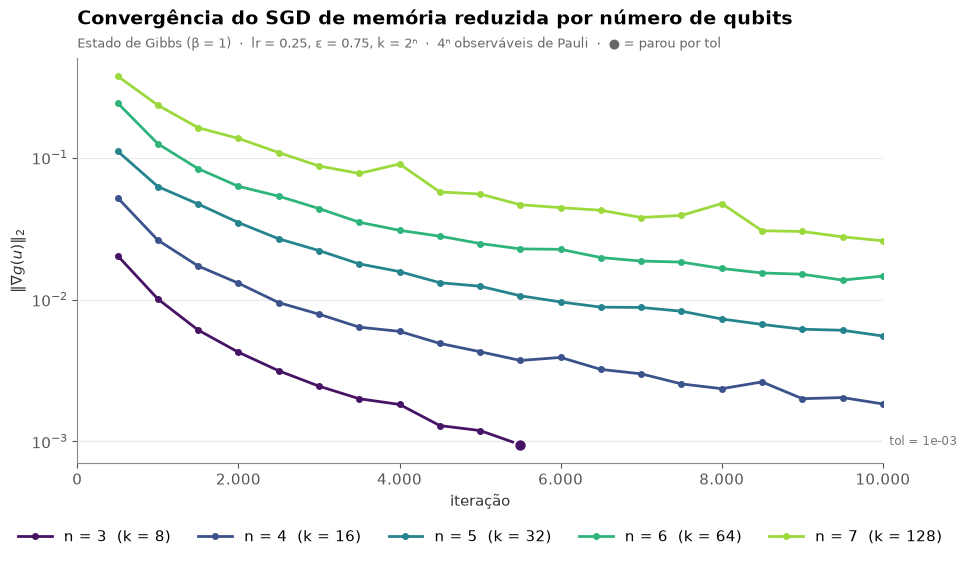

In [65]:
estilo = {
    "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8a8a", "axes.labelcolor": "#333333",
    "xtick.color": "#555555", "ytick.color": "#555555",
}

with plt.rc_context(estilo):
    fig, ax = plt.subplots(figsize=(10, 5.8))
    ns = list(curvas)
    cores = plt.cm.viridis(np.linspace(0.05, 0.85, len(ns)))

    for c, n in zip(cores, ns):
        h = curvas[n]
        ok = np.isfinite(h[:, 1]) & (h[:, 1] > 0)
        if not ok.any():
            continue
        ax.plot(h[ok, 0], h[ok, 1], "-o", color=c, lw=2, ms=4,
                label=f"n = {n}  (k = {2**n})", zorder=3)
        if parou_por_tol[n]:                       # destaca onde parou por tol
            ax.plot(h[ok, 0][-1], h[ok, 1][-1], "o", ms=9, color=c,
                    mec="white", mew=1.5, zorder=4)

    ax.axhline(tol, color="#9a9a9a", lw=0.8, ls=(0, (3, 4)), zorder=0)
    ax.text(1.008, tol, f"tol = {tol:.0e}", transform=ax.get_yaxis_transform(),
            va="center", fontsize=8.5, color="#777777")

    ax.set_yscale("log")
    ax.tick_params(which="minor", length=0)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{int(x):,}".replace(",", ".")))
    ax.set_xlim(0, max_iters)
    ax.set_axisbelow(True)
    ax.grid(True, which="major", axis="y", color="#e8e8e8", lw=0.8)
    ax.grid(False, axis="x")

    ax.set_xlabel("iteração")
    ax.set_ylabel(r"$\|\nabla g(u)\|_2$")
    ax.set_title("Convergência do SGD de memória reduzida por número de qubits",
                 loc="left", fontsize=14, fontweight="semibold", pad=24)
    ax.text(0, 1.025, f"Estado de Gibbs (β = {beta:g})  ·  lr = {lr}, ε = {epsilon}, k = 2ⁿ  ·  "
            f"4ⁿ observáveis de Pauli  ·  ● = parou por tol",
            transform=ax.transAxes, fontsize=9.5, color="#666666")

    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=len(ns),
              frameon=False, handlelength=2.2, columnspacing=1.8)
    fig.tight_layout()
    plt.show()

## 7. De quantos observáveis precisamos?

Avaliamos um estado-alvo à medida que aumentamos o número de observáveis medidos, verificando por meio da distância de traço, da norma de Frobenius e da função de Wigner a partir de quantos observáveis o estado reconstruído se aproxima suficientemente do estado-alvo.

 n    m  iters   ||grad||   d. traço  Frobenius  d. Wigner
 1    2     50    1.6e-16   3.81e-01   5.39e-01   5.40e-01
 1    4    250    6.3e-06   3.66e-06   5.17e-06   5.19e-06
 2    4    200    1.5e-06   4.23e-01   4.95e-01   4.94e-01
 2    8    300    4.8e-06   2.58e-01   2.68e-01   2.92e-01
 2   12   1050    9.1e-06   7.63e-06   7.64e-06   8.96e-06
 2   16   1300    7.5e-06   3.66e-06   4.63e-06   5.56e-06
 3    8    200    6.0e-07   5.57e-01   5.21e-01   7.43e-01
 3   16    200    2.6e-06   4.84e-01   4.37e-01   6.45e-01
 3   24    300    3.0e-06   3.79e-01   3.40e-01   4.98e-01
 3   32    750    8.4e-06   2.31e-01   2.11e-01   2.47e-01
 3   40    750    7.9e-06   2.31e-01   2.11e-01   2.47e-01
 3   48   1400    7.9e-06   1.99e-01   1.86e-01   2.26e-01
 3   56   2000    9.7e-06   5.72e-02   4.04e-02   3.48e-02
 3   64   5000    3.3e-05   1.17e-05   1.36e-05   1.69e-05
 4   16    200    6.9e-06   6.08e-01   4.75e-01   7.51e-01
 4   32    200    4.4e-06   5.95e-01   4.66e-01   7.46e-

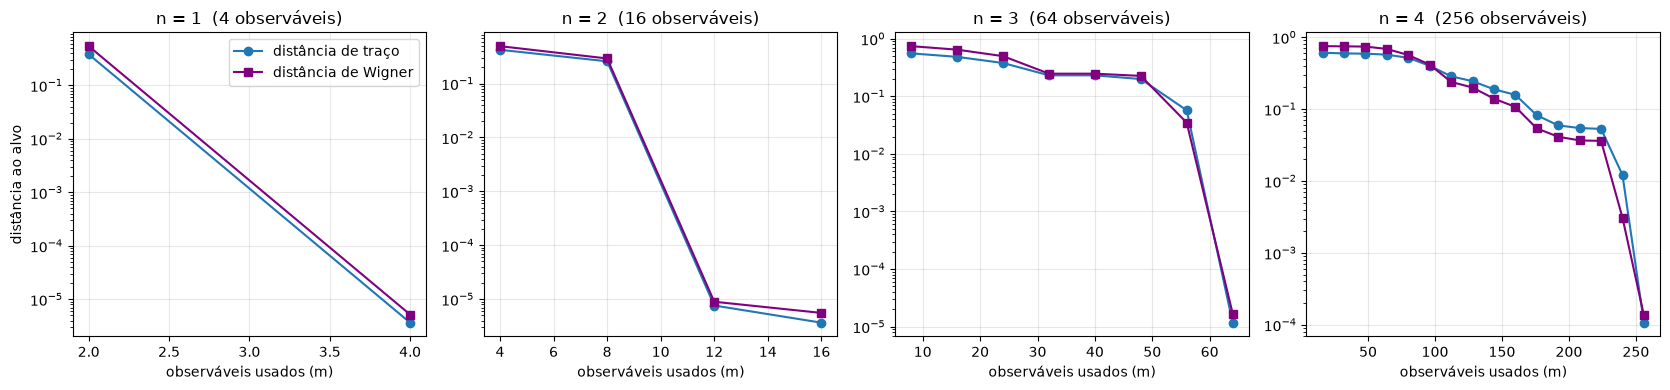

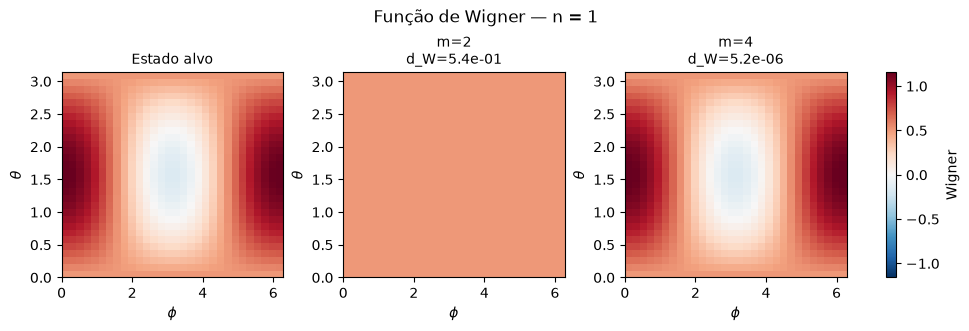

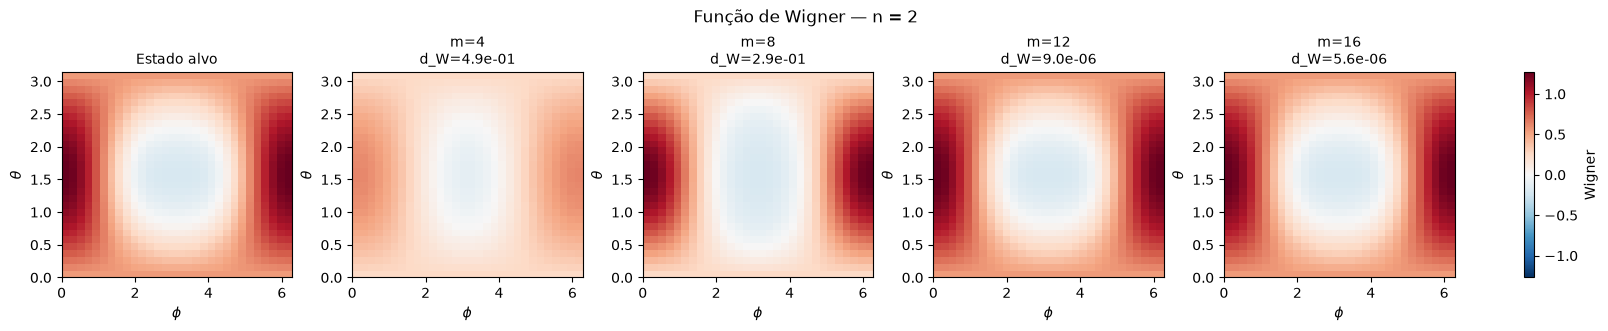

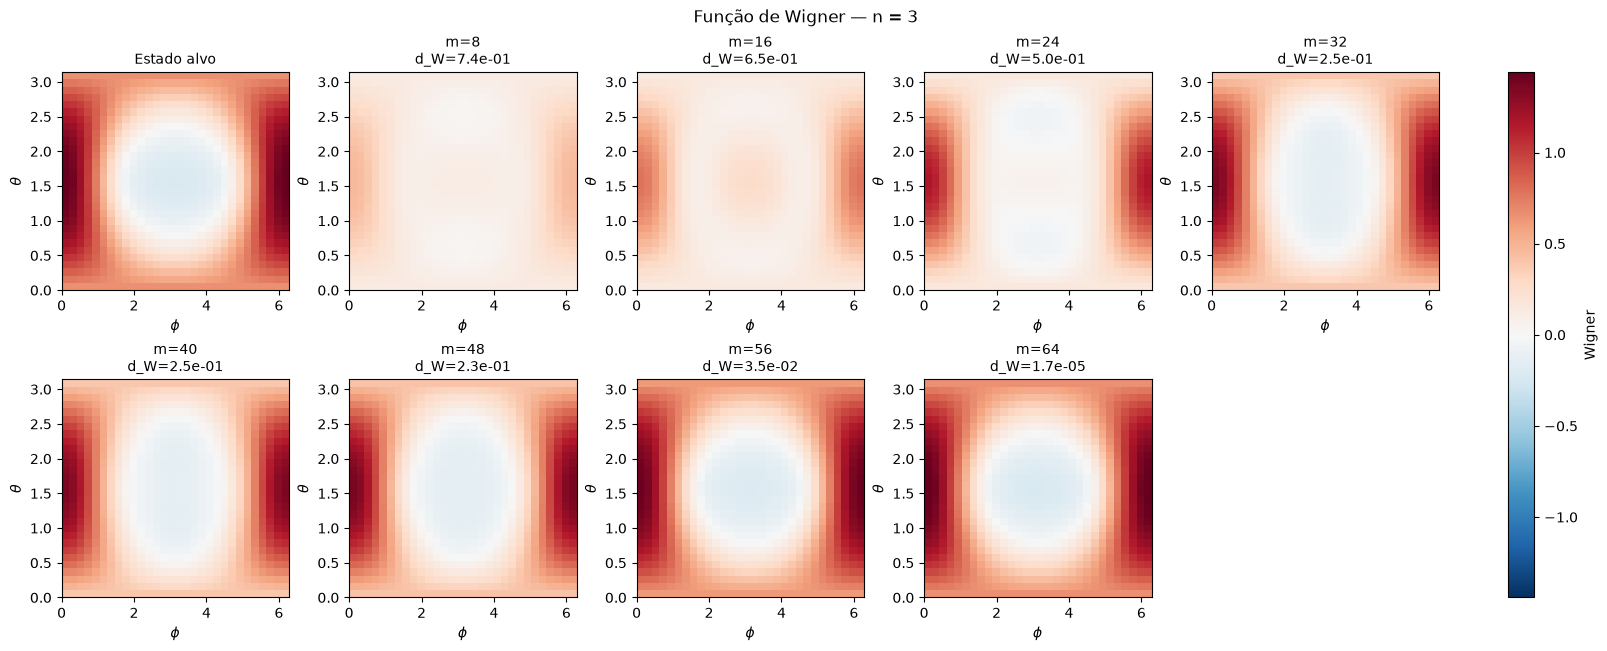

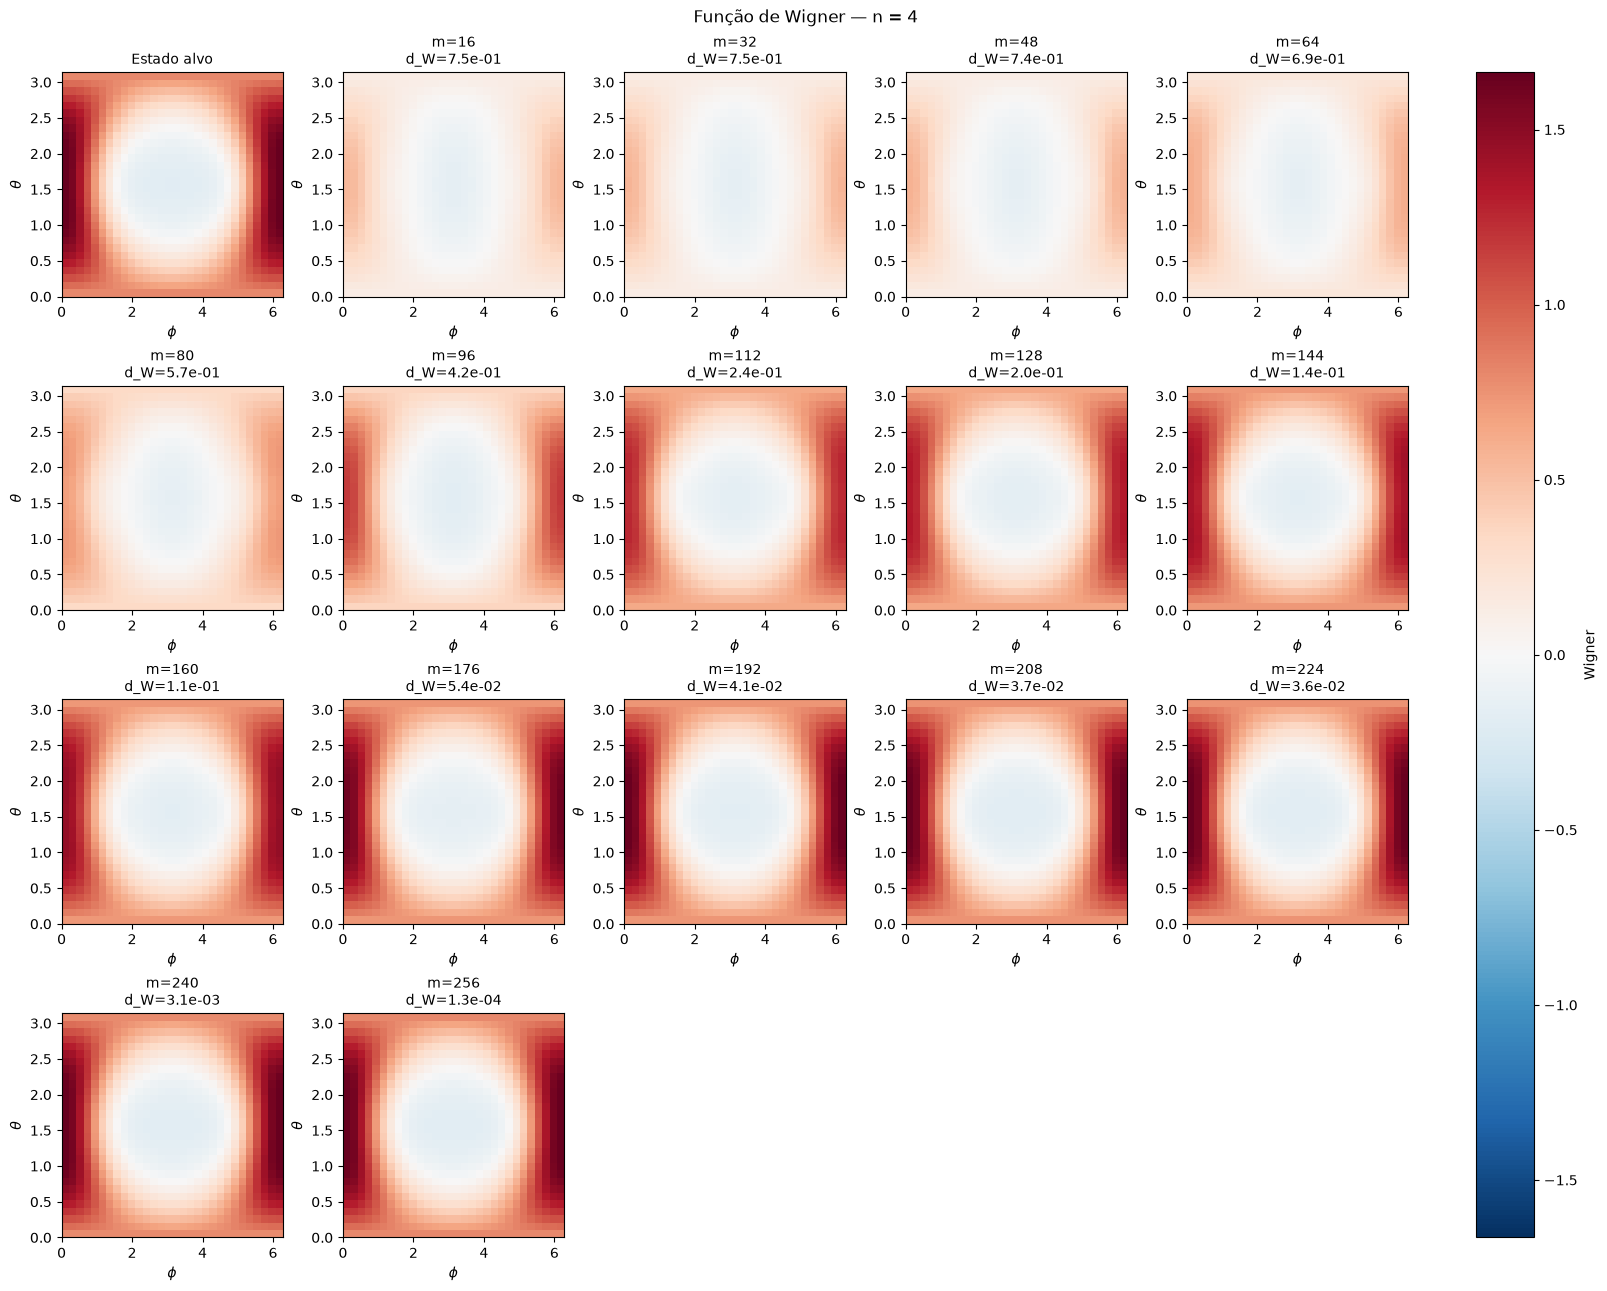

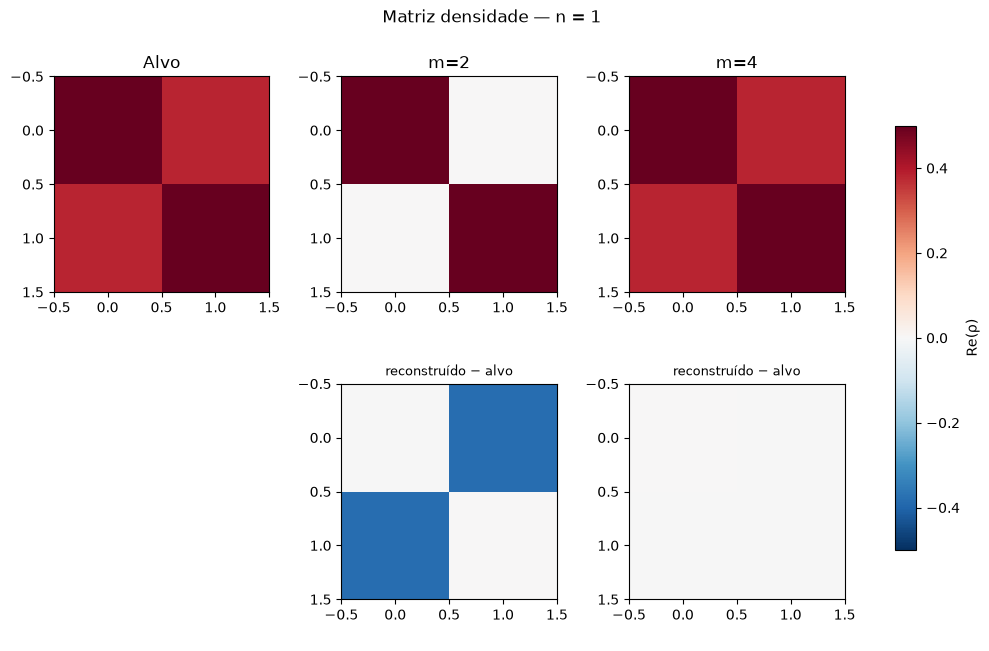

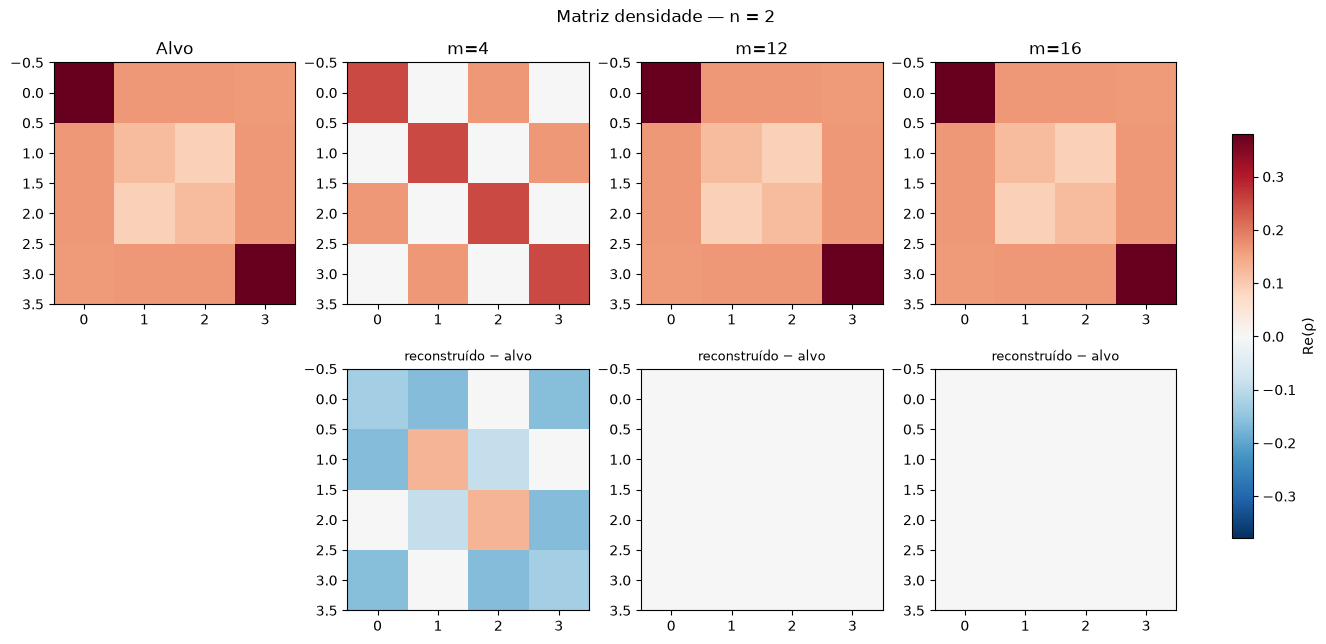

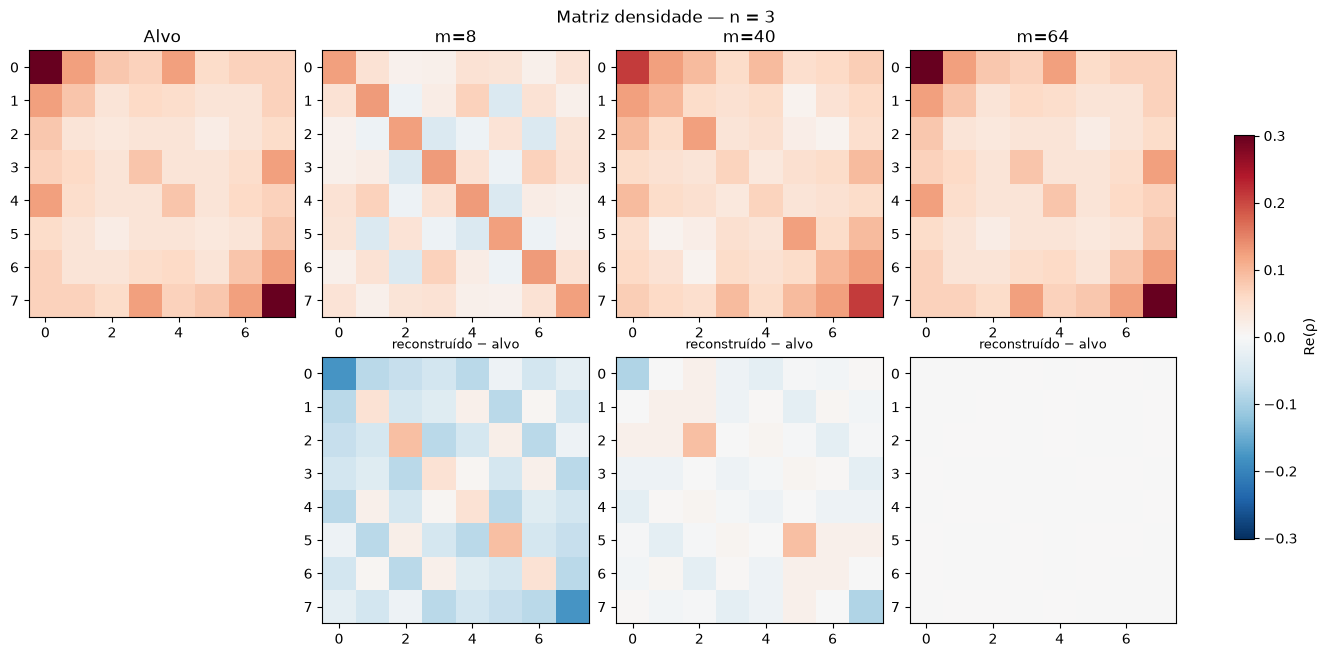

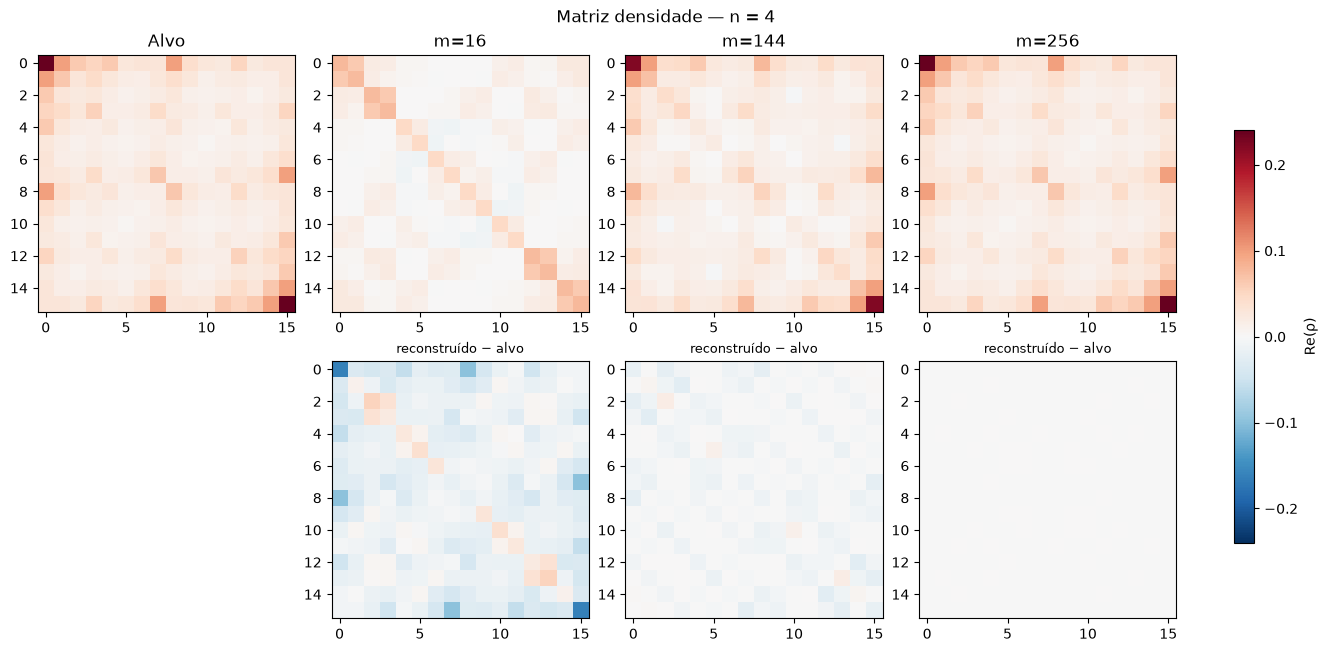

In [67]:
import numpy as np
import matplotlib.pyplot as plt

# ----------------------------------------------------------------------
# Parâmetros
# ----------------------------------------------------------------------
n_list = [1, 2, 3, 4]
beta = 1.0                   # temperatura inversa do Gibbs alvo
lr, epsilon = 0.25, 0.75
tol = 1e-5
max_iters = 5000
check_every = 50
seed = 0
steps_wigner = 30

# ----------------------------------------------------------------------
# Funções auxiliares
# ----------------------------------------------------------------------
def wigner_do_estado(rho, n):
    """Wigner de uma matriz densidade: soma ponderada da Wigner de cada autovetor."""
    rho_q = qtp.Qobj((rho + rho.conj().T) / 2, dims=[[2] * n, [2] * n])
    valores, kets = rho_q.eigenstates()
    return sum(
        val * np.real(np.asarray(wigner_transform(
            ket, j=0.5, fullparity=True, steps=steps_wigner, slicearray=["l"] * n)))
        for val, ket in zip(valores, kets) if val > 1e-12
    )

def dist_wigner(W, W_alvo):
    """Distância de Wigner: ||W - W_alvo|| / ||W_alvo||  (0 = idênticas)."""
    return np.linalg.norm(W - W_alvo) / np.linalg.norm(W_alvo)

# ----------------------------------------------------------------------
# Experimento
# ----------------------------------------------------------------------
res = {}
print(f"{'n':>2}{'m':>5}{'iters':>7}{'||grad||':>11}{'d. traço':>11}{'Frobenius':>11}{'d. Wigner':>11}")

for n in n_list:
    d = 2**n
    H = np.zeros((d, d), dtype=complex)

    alvo = estado_gibbs(hamiltoniano_ising(n), beta)
    W_alvo = wigner_do_estado(alvo.rho, n)
    nomes_todos, Q_todos = montar_observaveis_pauli(n)

    # ordem aleatória (identidade sempre primeiro); conjuntos aninhados
    rng = np.random.default_rng(seed)
    ordem = [0] + list(rng.permutation(np.arange(1, 4**n)))

    r = dict(rho_alvo=alvo.rho, W_alvo=W_alvo, m=[], rho=[], W=[], d_traco=[], d_wig=[])

    for m in range(2**n, 4**n + 1, 2**n):          # n=3: 8, 16, ..., 64
        idx = ordem[:m]
        nomes = [nomes_todos[i] for i in idx]
        Q = [Q_todos[i] for i in idx]
        q = qt.measure_observables(alvo, nomes)

        u0 = np.zeros(m)
        u0[0] = -epsilon * np.log(d)               # Tr(pi) começa em 1
        u, n_it, _ = sgd(H, Q, q, epsilon, k=max(1, m // 2), lr=lr,
                         n_iter=max_iters, tol=tol, seed=seed, u0=u0,
                         check_every=check_every)

        rho_rec = normalizar_rho(rho_a_partir_de_u(u, H, Q, epsilon))
        W = wigner_do_estado(rho_rec, n)

        d_traco = qt.trace_distance(alvo.rho, rho_rec)
        frob = qt.frobenius_distance(alvo.rho, rho_rec)
        d_wig = dist_wigner(W, W_alvo)
        g = np.linalg.norm(dual_gradient(u, H, Q, q, epsilon))

        r["m"].append(m); r["rho"].append(rho_rec); r["W"].append(W)
        r["d_traco"].append(d_traco); r["d_wig"].append(d_wig)
        print(f"{n:>2}{m:>5}{n_it:>7}{g:>11.1e}{d_traco:>11.2e}{frob:>11.2e}{d_wig:>11.2e}")

    res[n] = r

# ----------------------------------------------------------------------
# Figura 1: distância ao alvo x número de observáveis
# ----------------------------------------------------------------------
fig, axs = plt.subplots(1, len(n_list), figsize=(4.2 * len(n_list), 4))
axs = np.atleast_1d(axs)
for ax, n in zip(axs, n_list):
    r = res[n]
    ax.semilogy(r["m"], np.maximum(r["d_traco"], 1e-12), "o-", label="distância de traço")
    ax.semilogy(r["m"], np.maximum(r["d_wig"], 1e-12), "s-", label="distância de Wigner", color = "purple")
    ax.set_title(f"n = {n}  ({4**n} observáveis)")
    ax.set_xlabel("observáveis usados (m)")
    ax.grid(alpha=0.3)
axs[0].set_ylabel("distância ao alvo")
axs[0].legend()
fig.tight_layout()
plt.show()

# ----------------------------------------------------------------------
# Figura 2: evolução da função de Wigner (alvo + um painel por m)
# ----------------------------------------------------------------------
for n in n_list:
    r = res[n]
    paineis = [("Estado alvo", r["W_alvo"])] + [
        (f"m={m}\nd_W={dw:.1e}", W) for m, W, dw in zip(r["m"], r["W"], r["d_wig"])
    ]
    vmax = max(np.max(np.abs(W)) for _, W in paineis)
    ncols = min(len(paineis), 5)
    nrows = int(np.ceil(len(paineis) / ncols))

    fig, axs = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 3.2 * nrows),
                            constrained_layout=True)
    axs = np.atleast_1d(axs).ravel()
    for ax, (titulo, W) in zip(axs, paineis):
        im = ax.imshow(W, origin="lower", extent=[0, 2 * np.pi, 0, np.pi],
                       aspect="auto", cmap="RdBu_r", vmin=-vmax, vmax=vmax)
        ax.set_title(titulo, fontsize=10)
        ax.set_xlabel(r"$\phi$"); ax.set_ylabel(r"$\theta$")
    for ax in axs[len(paineis):]:
        ax.axis("off")
    fig.colorbar(im, ax=axs.tolist(), label="Wigner")
    fig.suptitle(f"Função de Wigner — n = {n}")
    plt.show()

# ----------------------------------------------------------------------
# Figura 3: alvo x reconstruído direto na matriz densidade
# (linha de cima: Re(rho); linha de baixo: reconstruído - alvo, mesma escala)
# ----------------------------------------------------------------------
for n in n_list:
    r = res[n]
    escolhidos = sorted({0, len(r["m"]) // 2, len(r["m"]) - 1})   # menor, médio, maior m
    vmax = np.max(np.abs(np.real(r["rho_alvo"])))

    fig, axs = plt.subplots(2, 1 + len(escolhidos), figsize=(3.3 * (1 + len(escolhidos)), 6.4),
                            constrained_layout=True)
    kw = dict(cmap="RdBu_r", vmin=-vmax, vmax=vmax)

    axs[0, 0].imshow(np.real(r["rho_alvo"]), **kw); axs[0, 0].set_title("Alvo")
    axs[1, 0].axis("off")
    for j, i in enumerate(escolhidos, start=1):
        rho_rec = r["rho"][i]
        im = axs[0, j].imshow(np.real(rho_rec), **kw)
        axs[0, j].set_title(f"m={r['m'][i]}")
        axs[1, j].imshow(np.real(rho_rec - r["rho_alvo"]), **kw)
        axs[1, j].set_title("reconstruído − alvo", fontsize=9)
    fig.colorbar(im, ax=axs.ravel().tolist(), shrink=0.7, label="Re(ρ)")
    fig.suptitle(f"Matriz densidade — n = {n}")
    plt.show()

### Documentação do Experimento: Convergência com o Número de Observáveis e Evolução de Wigner

#### 1. O que foi implementado
O experimento analisa como o estado reconstruído via regularização entrópica (SGD no problema dual) se aproxima do estado-alvo à medida que aumentamos a fração de observáveis de Pauli medidos, agora acompanhando essa convergência visualmente pela **função de Wigner de spin** usando apenas as funções já implementadas no projeto e funções da biblioteca **QuTiP**:

1. **Escopo simplificado (1 a 4 qubits, 1 exemplo por $n$):**
   - Rodamos para `n_list = [1, 2, 3, 4]` usando uma única semente (`seed = 0`).
   - Para cada $n$ (dimensão $d = 2^n$), o estado-alvo `estado_alvo` é o estado térmico de Gibbs $\rho_{\text{alvo}} = e^{-\beta H_{\text{Ising}}}/Z$ (com $\beta = 1.0$) gerado por `estado_gibbs(hamiltoniano_ising(n), beta)`.
   - Os $4^n$ observáveis de Pauli são ordenados mantendo a identidade $I^{\otimes n}$ na primeira posição (para garantir $\operatorname{Tr}(\pi) = 1$) e permutando os demais. O número de observáveis medidos $m$ cresce em passos de $2^n$ (de $2^n$ até $4^n$), de forma aninhada (cada conjunto contém o anterior).
   - Em cada passo $m > 0$, resolvemos o problema dual via `er.sgd(...)` com ponto inicial $u_0 = [-\varepsilon\ln d, 0, \dots, 0]$ (para começar com $\operatorname{Tr}(\pi)=1$) e reconstruímos a matriz densidade normalizada `rho_rec = normalizar_rho(rho_a_partir_de_u(u, H, Q, epsilon))`.

2. **Transformada de Wigner com QuTiP:**
   - Como `qutip.wigner.wigner_transform` espera kets puros (na versão 5.x, objetos `Qobj` de matriz densidade possuem `type == "oper"` enquanto `wigner_transform` verifica `"operator"`), aplicamos a decomposição espectral diretamente via QuTiP:
     - Convertemos a matriz hermitizada em `qtp.Qobj(..., dims=[[2]*n, [2]*n])`.
     - Extraímos autovalores e autokets com `rho_qobj.eigenstates()`.
     - Pela linearidade da transformada de Wigner, somamos $\sum_{\lambda_i > 10^{-12}} \lambda_i \, W(|\psi_i\rangle)$, chamando `wigner_transform(ket, j=0.5, fullparity=True, steps=30, slicearray=["l"]*n)`.
   - Para `m = 0`, calculamos a função de Wigner do **estado-alvo original** (`wigners_alvo[n]`), antes de reconstruir qualquer aproximação.
   - Em cada iteração $m$, calculamos a função de Wigner do **estado reconstruído** (`wigners_rec[n]`), permitindo observar graficamente como a distribuição evolui desde o caso subdeterminado até reproduzir o alvo.

---

#### 2. Métricas e tipos de distância utilizados
* **Distância de traço (`dist. traço` / `d` nos painéis):**
  Calculada por `qt.trace_distance(estado_alvo.rho, rho_rec)`:
  $$D(\rho_{\text{alvo}}, \rho_{\text{rec}}) = \frac{1}{2}\,\|\rho_{\text{alvo}} - \rho_{\text{rec}}\|_1 = \frac{1}{2}\sum_i |\lambda_i(\rho_{\text{alvo}} - \rho_{\text{rec}})|$$
  onde $\lambda_i$ são os autovalores da diferença hermitiana. É uma métrica física padrão entre estados quânticos ($0 \le D \le 1$): mede a maior diferença possível entre probabilidades de medição de qualquer observável nos dois estados. É usada para definir o `limiar = 1e-2`, no gráfico de convergência e no título de cada painel de Wigner (`d=...`).

* **Norma de Frobenius (`norma Frob.`):**
  Calculada por `qt.frobenius_distance(estado_alvo.rho, rho_rec)`:
  $$\|\rho_{\text{alvo}} - \rho_{\text{rec}}\|_F = \sqrt{\operatorname{Tr}\left((\rho_{\text{alvo}} - \rho_{\text{rec}})^\dagger(\rho_{\text{alvo}} - \rho_{\text{rec}})\right)}$$
  Mede a distância euclidiana entre as matrizes densidade ($\|\cdot\|_F \ge 0$, sendo $0$ quando os estados são idênticos).

* **Norma do gradiente dual (`||grad||`):**
  Calculada por `np.linalg.norm(er.dual_gradient(u, H, Q, q, epsilon))`, corresponde à norma euclidiana $\|\nabla g(u)\|_2$, cujas componentes são $\operatorname{Tr}(Q_i \pi(u)) - q_i$. Mede o quanto o estado reconstruído satisfaz as $m$ restrições medidas e serve como critério de parada do SGD (`tol = 1e-5`).

* **Diferença máxima de Wigner (`diff Wigner`):**
  Calculada por `np.max(np.abs(W - wigners_alvo[n]))`, corresponde à norma $L_\infty$ (distância máxima ponto a ponto na grade $(\theta, \phi)$) entre a função de Wigner reconstruída e a do estado-alvo.

---

#### 3. O que representam os eixos nos gráficos

1. **Gráfico de distância de traço vs. número de observáveis (4 painéis, um por $n$):**
   * **Eixo horizontal ($x$):** `observáveis medidos (m)` — quantidade de observáveis de Pauli fornecidos ao algoritmo (de $2^n$ até $4^n$).
   * **Eixo vertical ($y$, escala logarítmica):** `distância de traço ao alvo` $D(\rho_{\text{alvo}}, \rho_{\text{rec}})$. A linha horizontal tracejada indica `limiar = 1e-2`.

2. **Mapas da evolução da função de Wigner (um conjunto de painéis para cada $n$):**
   * **Eixo horizontal ($\phi \in [0, 2\pi]$):** ângulo **azimutal** na esfera de Bloch / espaço de fase de spin $SU(2)$ (rotação no plano equatorial $XY$).
   * **Eixo vertical ($\theta \in [0, \pi]$):** ângulo **polar (colatitude)** na esfera de Bloch ($\theta = 0$ corresponde ao polo norte $|0\rangle$, $\theta = \pi/2$ ao equador e $\theta = \pi$ ao polo sul $|1\rangle$).
   * **Significado da fatia (`slicearray=["l"]*n`, `fullparity=True`):** para $n$ qubits ($j = 1/2$ por qubit), a função de Wigner completa vive em um produto de $n$ esferas ($2n$ ângulos). O parâmetro `"l"` seleciona a fatia de ângulos iguais (*equal-angle slice*), avaliando todos os qubits simultaneamente no mesmo par $(\theta, \phi)$, enquanto `fullparity=True` usa o operador de paridade do grupo $SU(2^n)$ completo.
   * **Escala de cores (`Wigner`, mapa `RdBu_r` simétrico `[-vmax, vmax]`):** indica o valor da função de quase-probabilidade de Wigner $W(\theta, \phi)$ (vermelho = valores positivos, branco = zero, azul = valores negativos causados por coerência/interferência quântica). Todos os painéis de um mesmo $n$ compartilham a mesma escala de cores para permitir comparação visual direta entre cada iteração `m` e o painel `Estado alvo`.
